# LSTM exploration

This notebook includes the best-performing models for LSTM models, both global and individual, and non-recurrent models. Some best-performing municipalities repeat themselves, so I only plot them once.

In [1]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms

sys.path.append('../')

from model_recurrent import Model

In [2]:
df = pd.read_csv("../full_data.csv")

# Best-performing

For non-recurrent models, the best are: 117, 101, 201, 110.

In [4]:
confints = pd.read_csv(f"../data/metrics/nrmse_lstm_confint.csv")
confints.head()

,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
0,101,0.364140,0.289012,0.476068,0.611888,0.521367,0.708155,0.363290,0.306951,0.404951,0.506249,0.437141,0.558422
1,102,1.061527,0.821540,1.261453,0.912163,0.605214,1.154129,1.217134,1.097229,1.341808,1.128394,0.965995,1.294708
2,103,0.331629,0.256005,0.414361,0.590405,0.486385,0.674933,0.906881,0.606200,1.029905,0.744337,0.503072,0.825934
3,104,1.425756,1.054345,1.729534,1.315338,0.904635,1.627707,1.568818,1.327075,1.758772,1.573887,1.282681,1.770329
4,105,0.924526,0.576664,1.151055,0.948123,0.617297,1.170258,2.262762,1.008579,2.468795,2.254943,0.370043,2.423143


## Global

In [5]:
sorted_confint_global = confints.sort_values(by = "test_point_global", ascending = True)
display(sorted_confint_global.head(4))
display(sorted_confint_global.tail(4))

,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
16,117,3.808581,1.030647,4.432442,3.743615,1.441074,4.389984,0.363001,0.284959,0.422484,0.102618,0.077416,0.119000
0,101,0.364140,0.289012,0.476068,0.611888,0.521367,0.708155,0.363290,0.306951,0.404951,0.506249,0.437141,0.558422
20,201,0.636366,0.539425,0.747681,0.583365,0.530762,0.644419,0.490483,0.380075,0.575095,0.627000,0.499658,0.739962
65,601,0.830225,0.739537,0.939803,0.653776,0.571426,0.741106,0.898994,0.792499,1.031763,0.675486,0.498498,0.880491


,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
41,306,1.984974,0.390741,2.700182,1.974673,0.530231,2.727920,2.639003,0.409980,3.329890,2.639142,1.258417,3.335384
30,211,1.114189,0.109745,1.642726,1.122045,0.138611,1.650900,2.932111,0.045943,2.947049,2.927348,0.084179,2.942330
23,204,2.983185,1.795284,3.808892,2.818299,1.850434,3.553463,3.069015,2.226303,3.951727,3.100237,2.207348,4.209190
15,116,3.269016,2.344266,4.043528,2.195519,1.642540,3.007023,3.644984,1.170698,3.669634,3.605874,0.339951,3.608721


## Individual

In [6]:
sorted_confint_ind = confints.sort_values(by = "test_point_ind", ascending = True)
display(sorted_confint_ind.head(4))
display(sorted_confint_ind.tail(4))

,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
16,117,3.808581,1.030647,4.432442,3.743615,1.441074,4.389984,0.363001,0.284959,0.422484,0.102618,0.077416,0.119000
0,101,0.364140,0.289012,0.476068,0.611888,0.521367,0.708155,0.363290,0.306951,0.404951,0.506249,0.437141,0.558422
20,201,0.636366,0.539425,0.747681,0.583365,0.530762,0.644419,0.490483,0.380075,0.575095,0.627000,0.499658,0.739962
48,405,0.889232,0.537668,1.137648,0.863542,0.501973,1.118943,0.821138,0.008410,1.109346,0.815616,0.103319,1.106745


,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
81,706,0.883884,0.756864,1.020677,0.720671,0.597889,0.843765,2.642020,1.813065,4.134847,1.330397,0.861709,1.684452
30,211,1.114189,0.109745,1.642726,1.122045,0.138611,1.650900,2.932111,0.045943,2.947049,2.927348,0.084179,2.942330
23,204,2.983185,1.795284,3.808892,2.818299,1.850434,3.553463,3.069015,2.226303,3.951727,3.100237,2.207348,4.209190
15,116,3.269016,2.344266,4.043528,2.195519,1.642540,3.007023,3.644984,1.170698,3.669634,3.605874,0.339951,3.608721


# Global models

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(500, 12, 29))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 12, 29))']
  warnings.warn(msg)


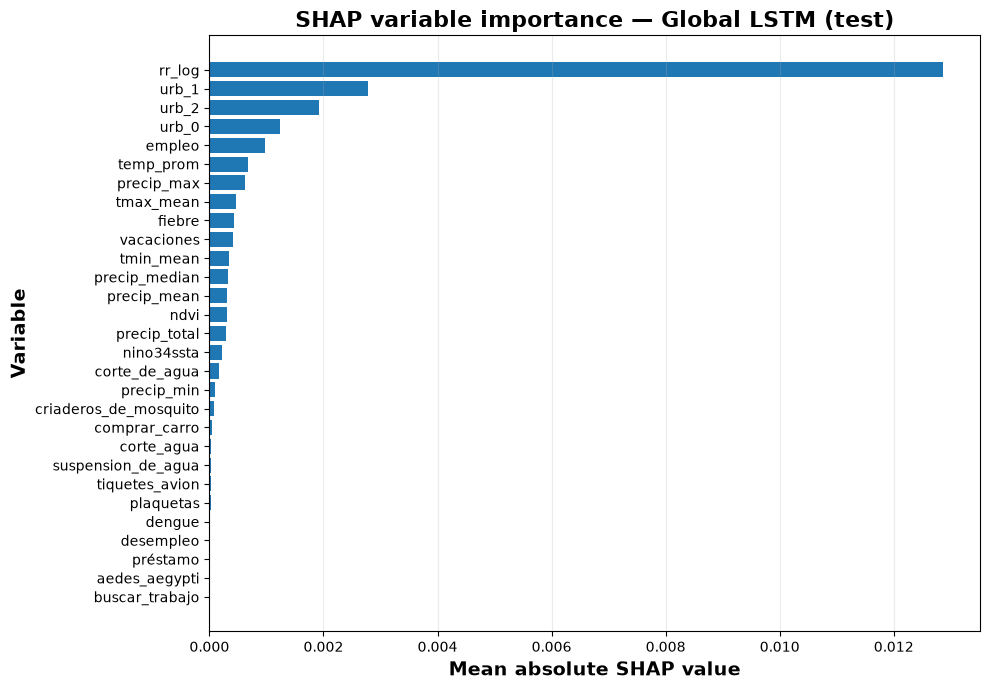

In [4]:
model0 = Model(df, "full")

shap_values_global, importance_global, fig, ax = (
    model0.shap_lstm_full(
        split="test"
    )
)

# Best-performing

BlockBootstrap ACI LSTM execution time: 397.14 seconds


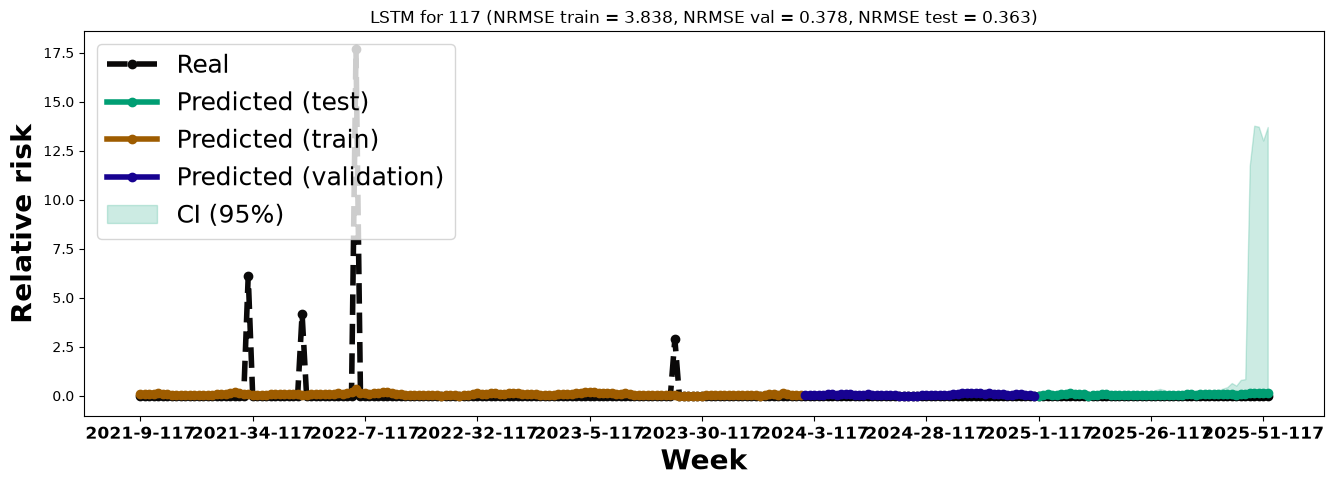

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Predicting test observation 1/52
Predicting test observation 2/52
Predicting test observation 3/52
Predicting test observation 4/52
Predicting test observation 5/52
Predicting test observation 6/52
Predicting test observation 7/52
Predicting test observation 8/52
Predicting test observation 9/52
Predicting test observation 10/52
Predicting test observation 11/52
Predicting test observation 12/52
Predicting test observation 13/52
Predicting test observation 14/52
Predicting test observation 15/52
Predicting test observation 16/52
Predicting test observation 17/52
Predicting test observation 18/52
Predicting test observation 19/52
Predicting test observation 20/52
Predicting test observation 21/52
Predicting test observation 22/52
Predicting test observation 23/52
Predicting test observation 24/52
Predicting test observation 25/52
Predicting test observation 26/52
Predicting test observation 27/52
Predicting test observation 28/52
Predicting test observation 29/52
Predicting test observa

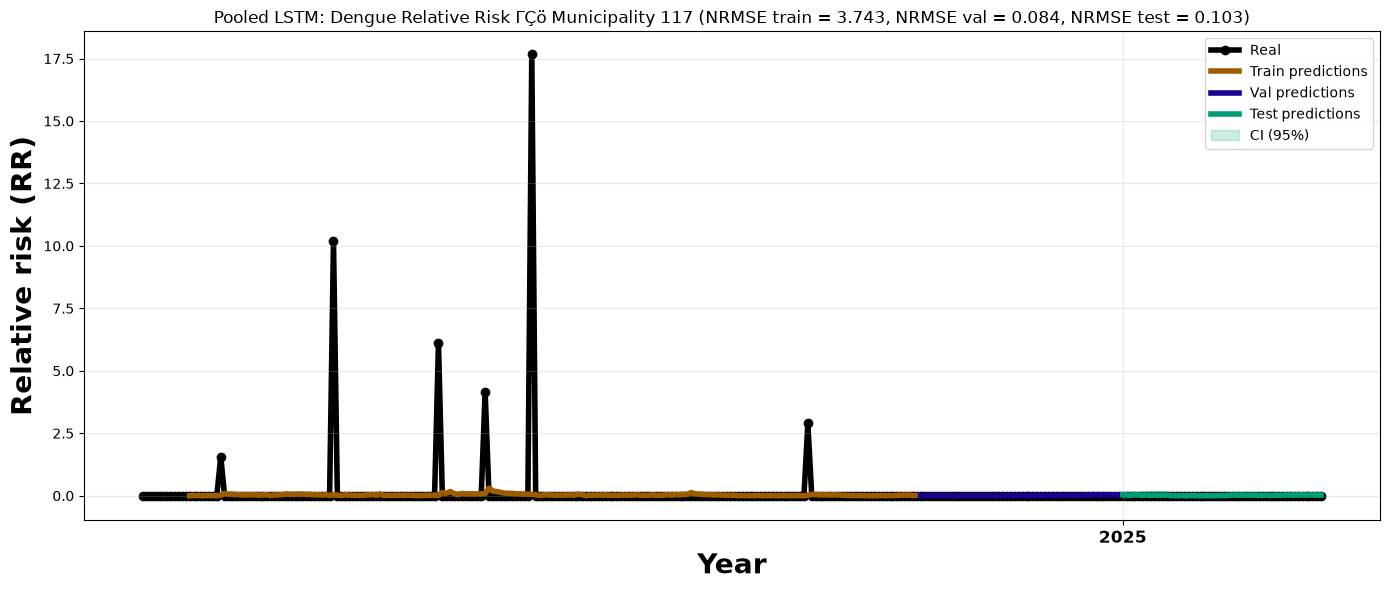

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 52, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 52, 27))']
  warnings.warn(msg)


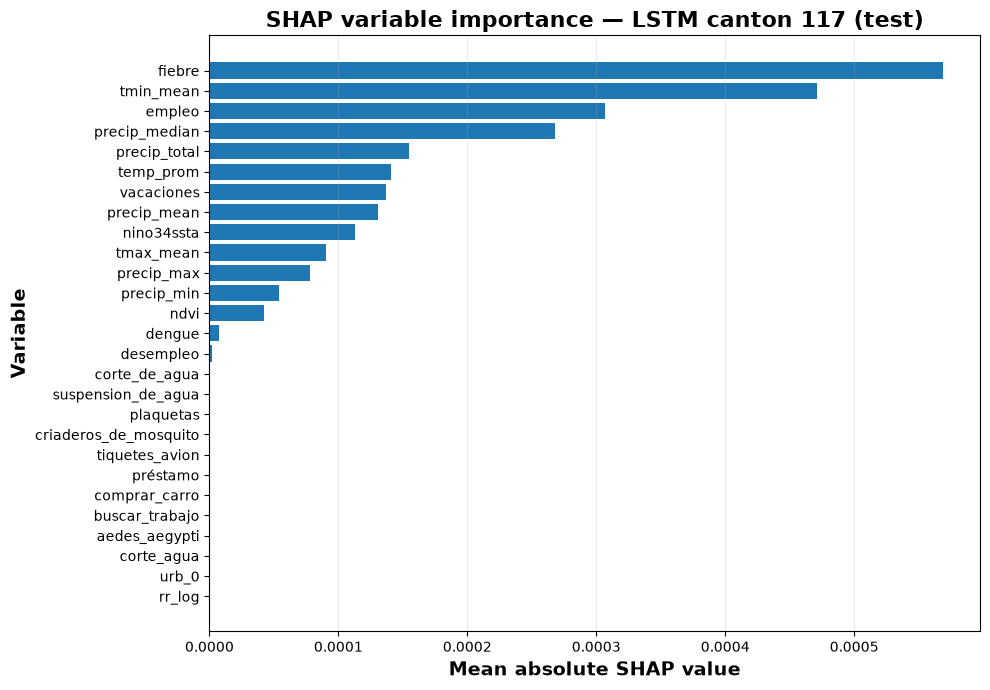

In [5]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 370.90 seconds


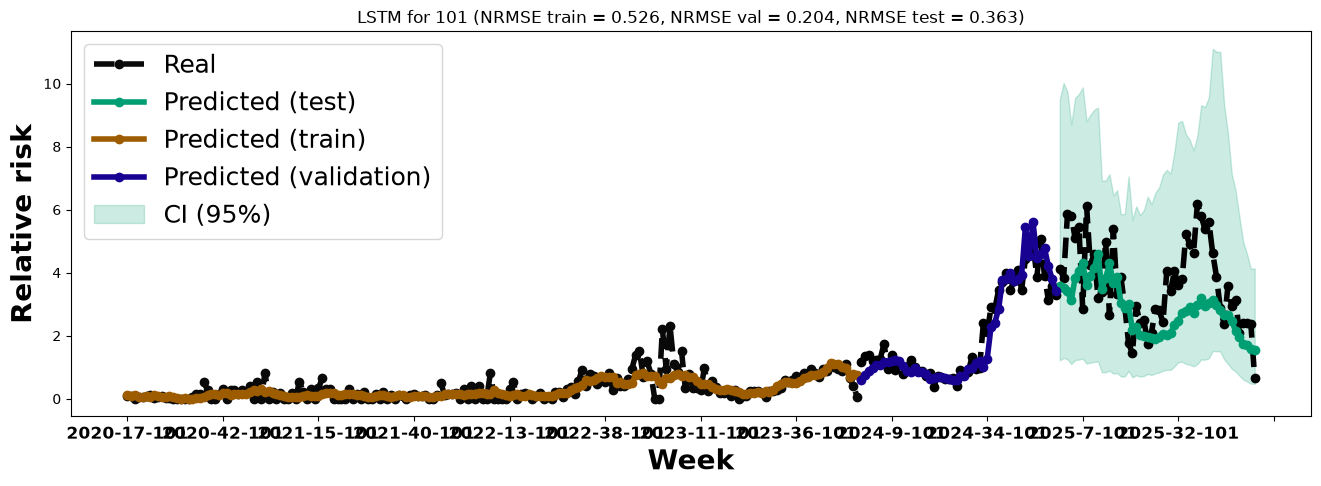

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 372.64 seconds


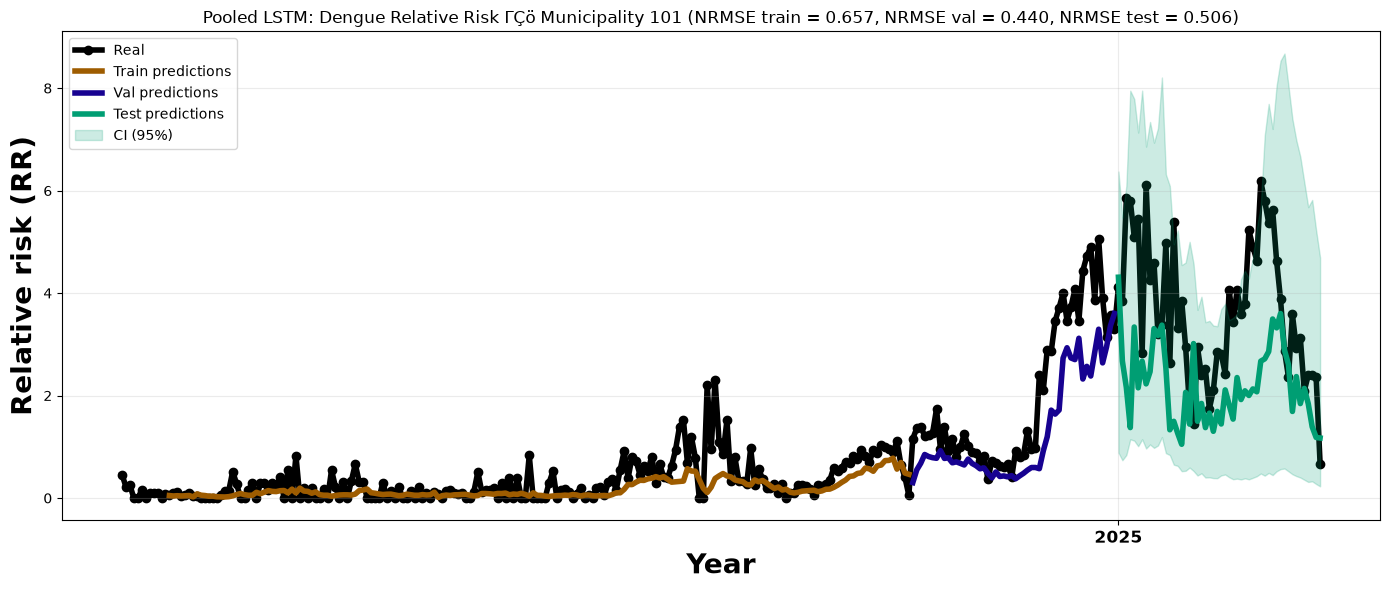

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 8, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 8, 27))']
  warnings.warn(msg)


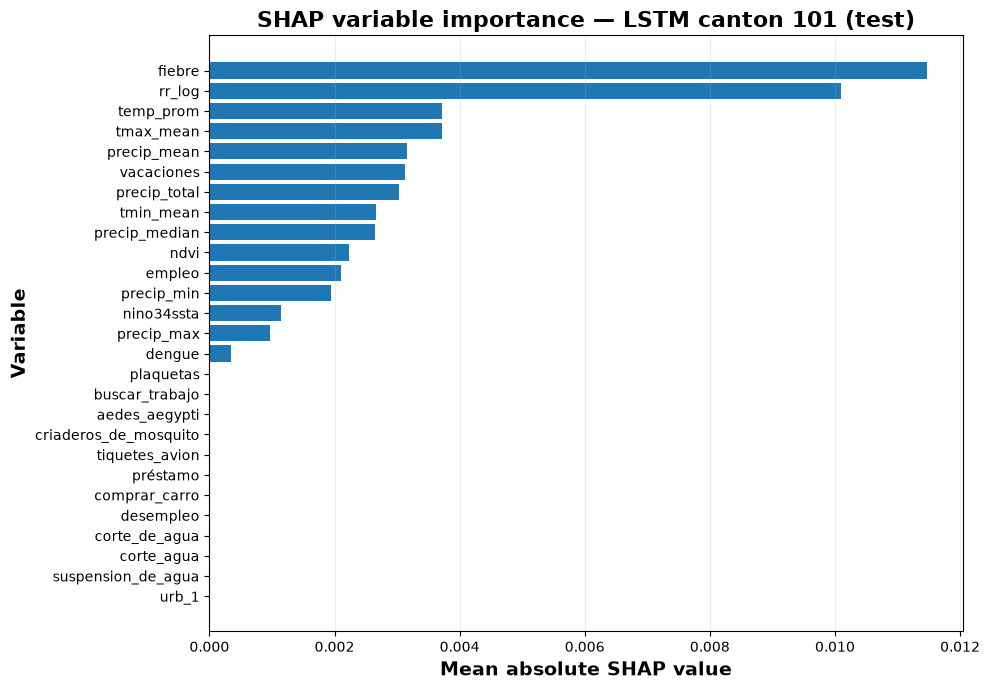

In [3]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 344.08 seconds


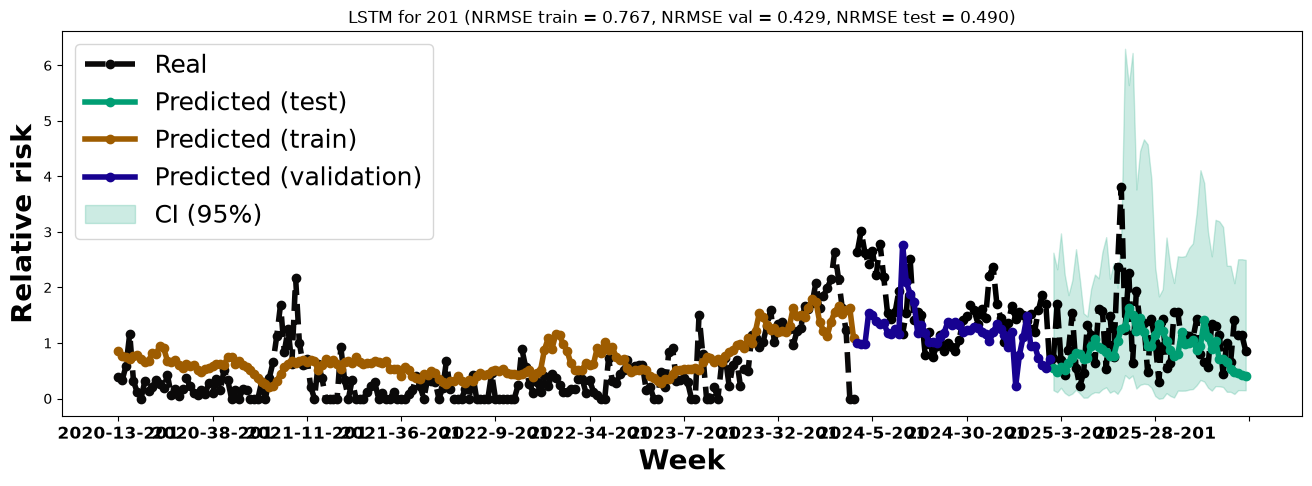

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 359.40 seconds


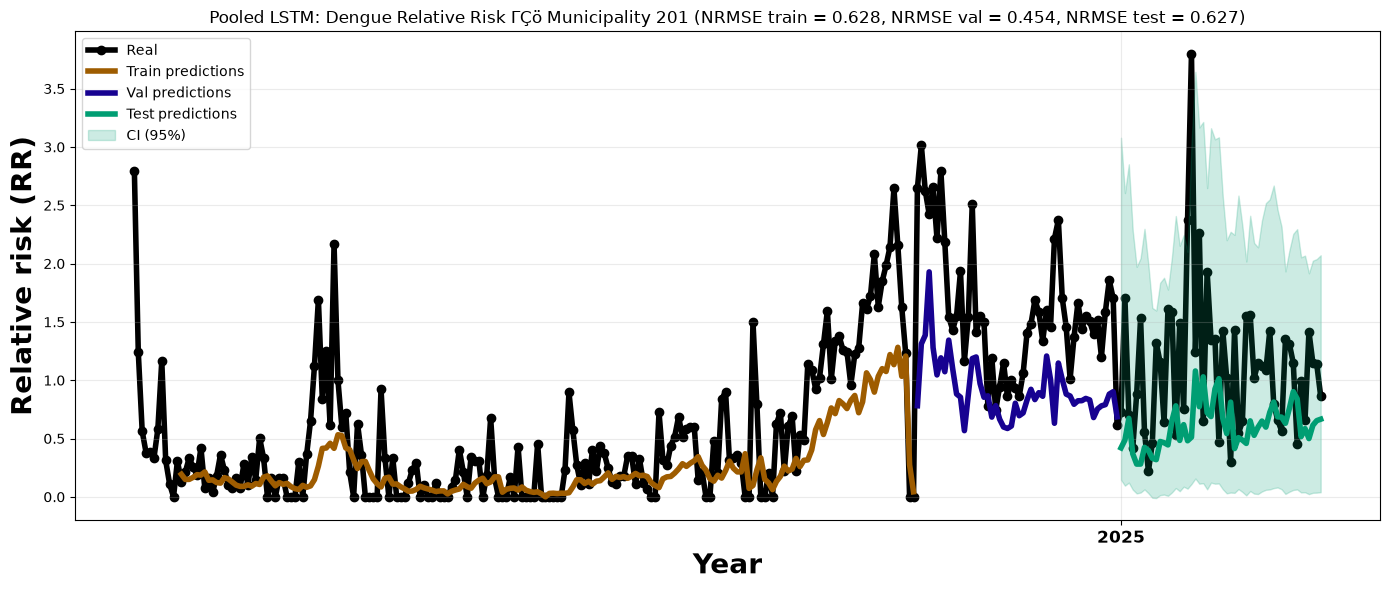

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 4, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 4, 27))']
  warnings.warn(msg)


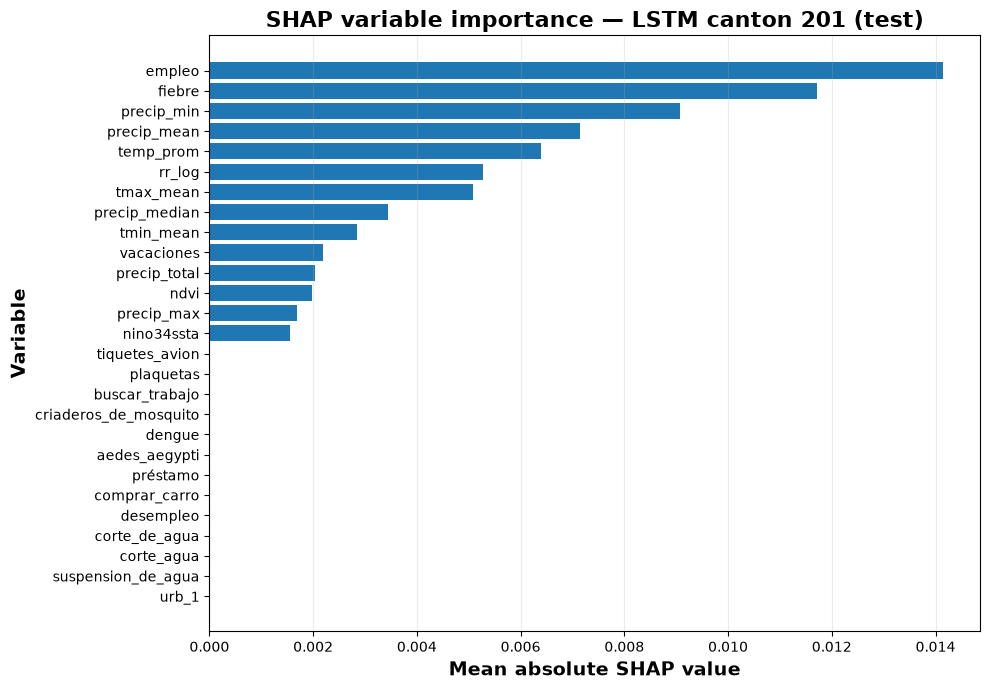

In [4]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 409.68 seconds


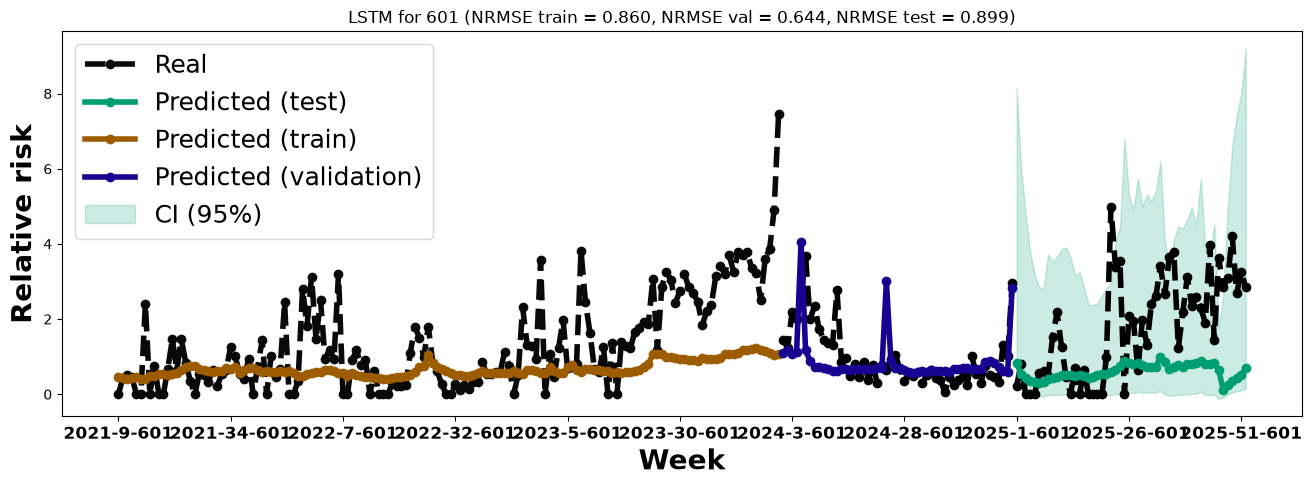

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 422.40 seconds


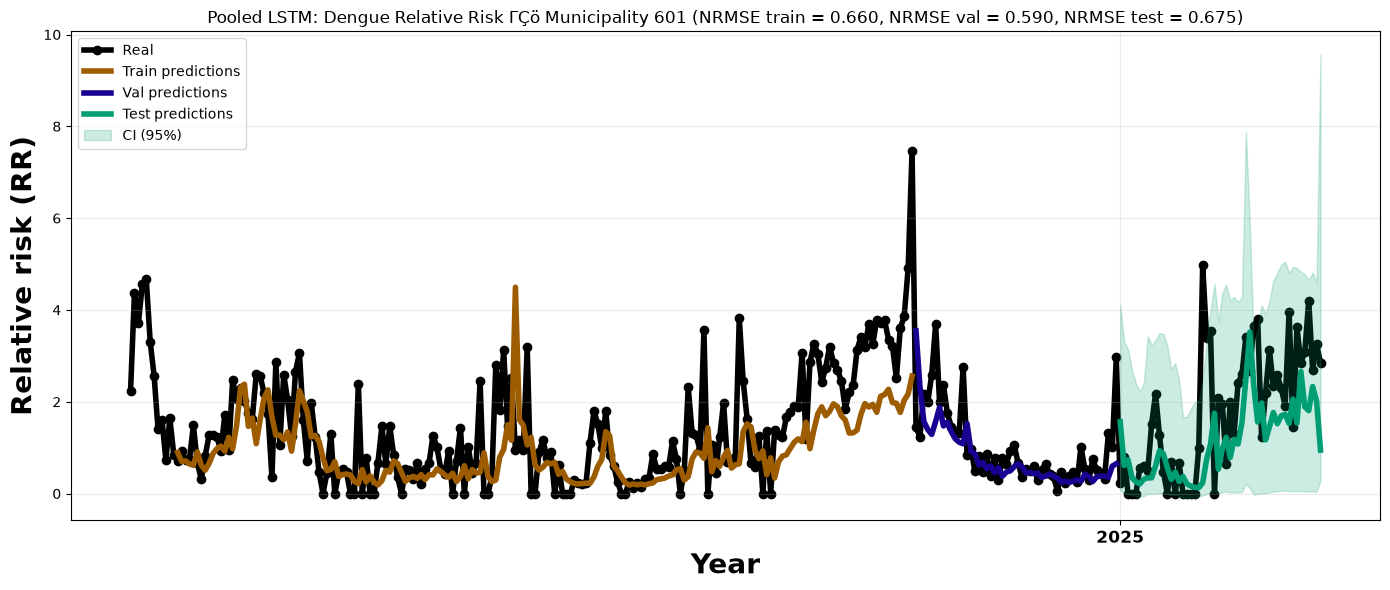

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 52, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 52, 27))']
  warnings.warn(msg)


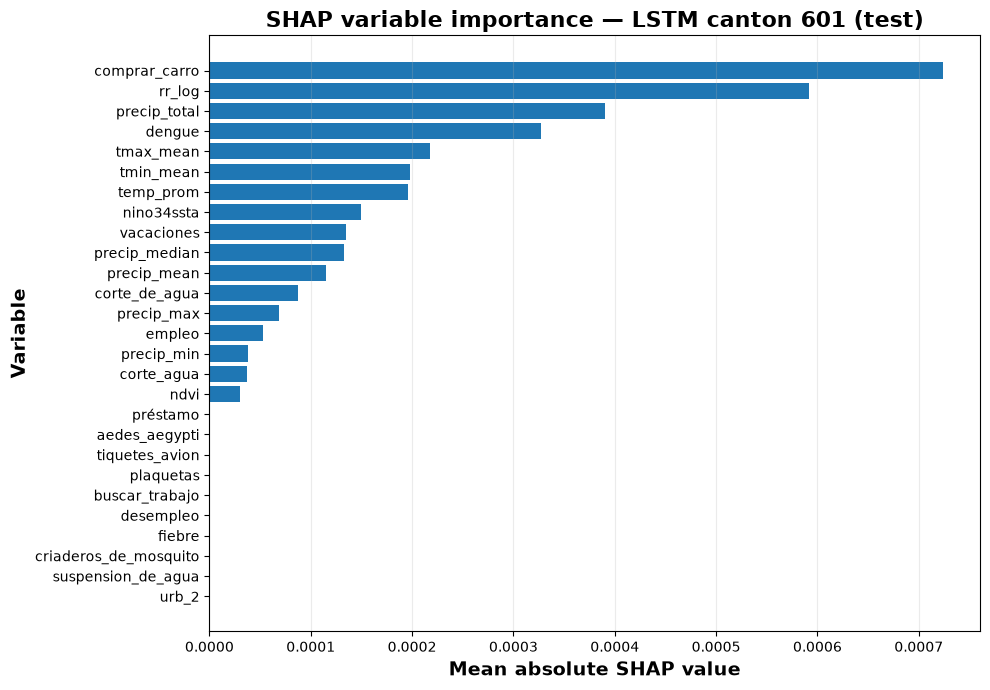

In [5]:
model0 = Model(df, "601")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 423.42 seconds


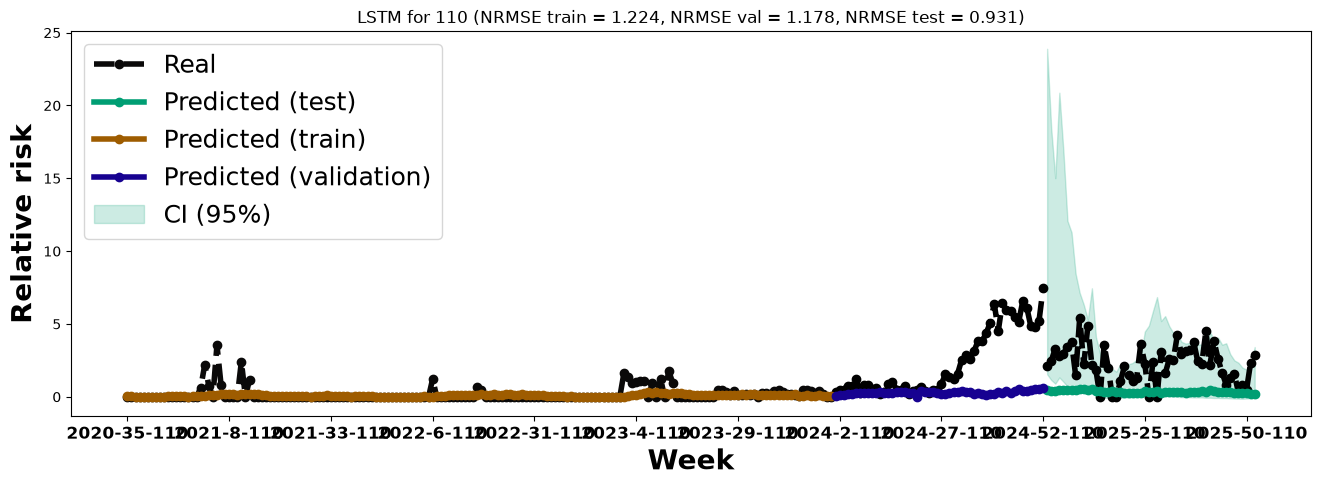

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 372.73 seconds


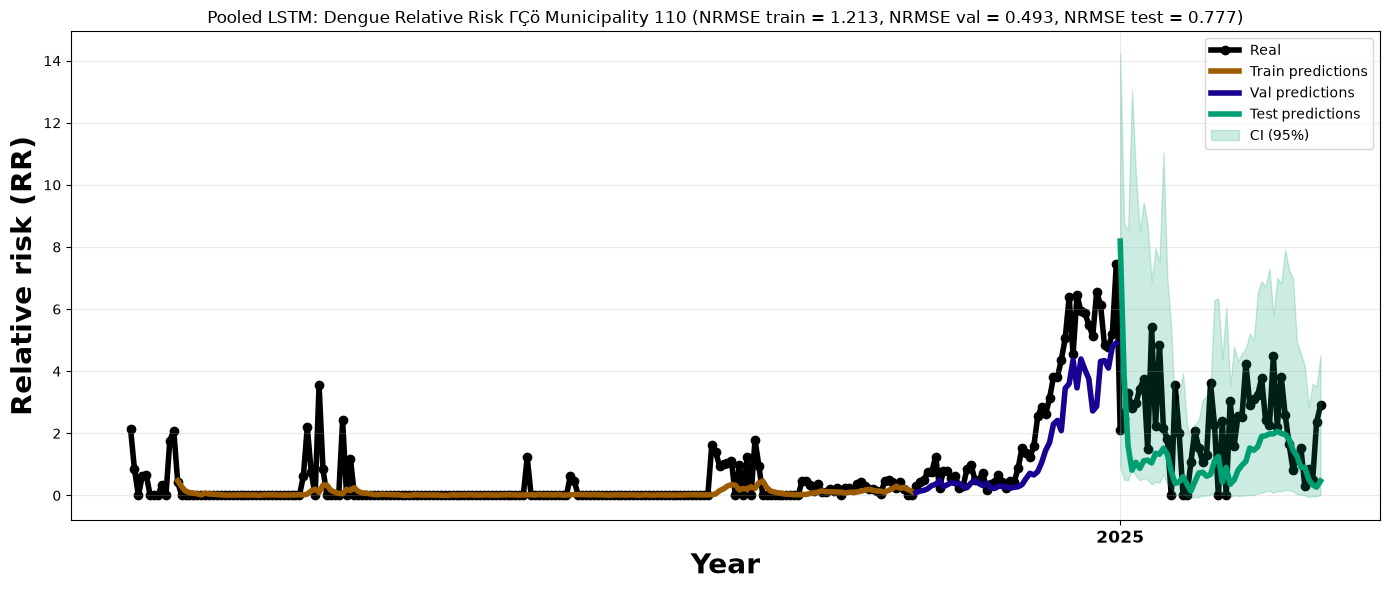

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 26, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 26, 27))']
  warnings.warn(msg)


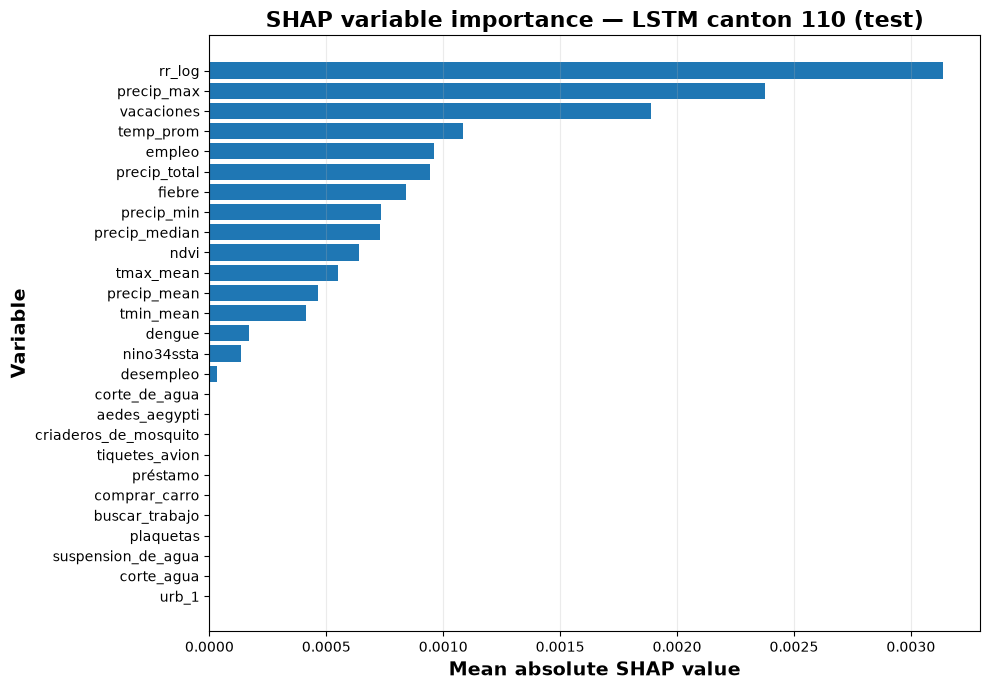

In [6]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

# NRMSE comparison with non-recurrent models

In [7]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms

def plot_nrmse_confint_past(dataset, type_scope):

    non_recurrent = pd.read_csv(
        f"../data/metrics/best_non_recurrent_confint_test.csv"
    ) 

    recurrent = pd.read_csv(
            f"../data/metrics/nrmse_lstm_confint.csv"
        )

    x = np.arange(len(non_recurrent))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in non_recurrent.iterrows():
        # Plotting the individual model NRMSE results

        mean_col = row["best_mean_model"]
        lower_col = mean_col.replace("mean_", "lower_")
        upper_col = mean_col.replace("mean_", "upper_")
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in recurrent.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_{type_scope}"
        lower_col = f"{dataset}_lower_{type_scope}"
        upper_col = f"{dataset}_upper_{type_scope}"

        x_full = x[i] + 0.8

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(non_recurrent["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="Non-recurrent", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label=f"{type_scope}", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

C:\Windows\Temp\ipykernel_13972\116549224.py:124: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


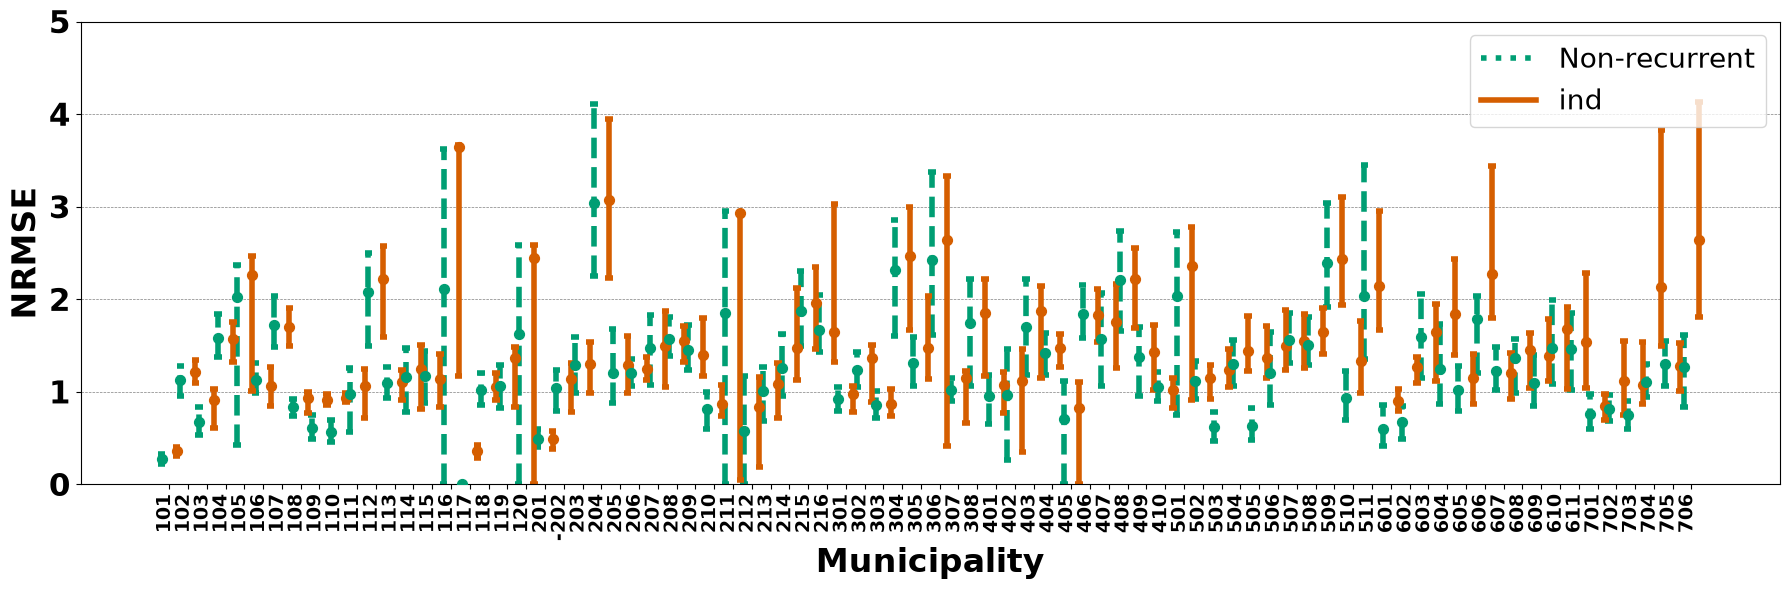

In [8]:
plot_nrmse_confint_past("test", "ind")

C:\Windows\Temp\ipykernel_13972\116549224.py:124: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


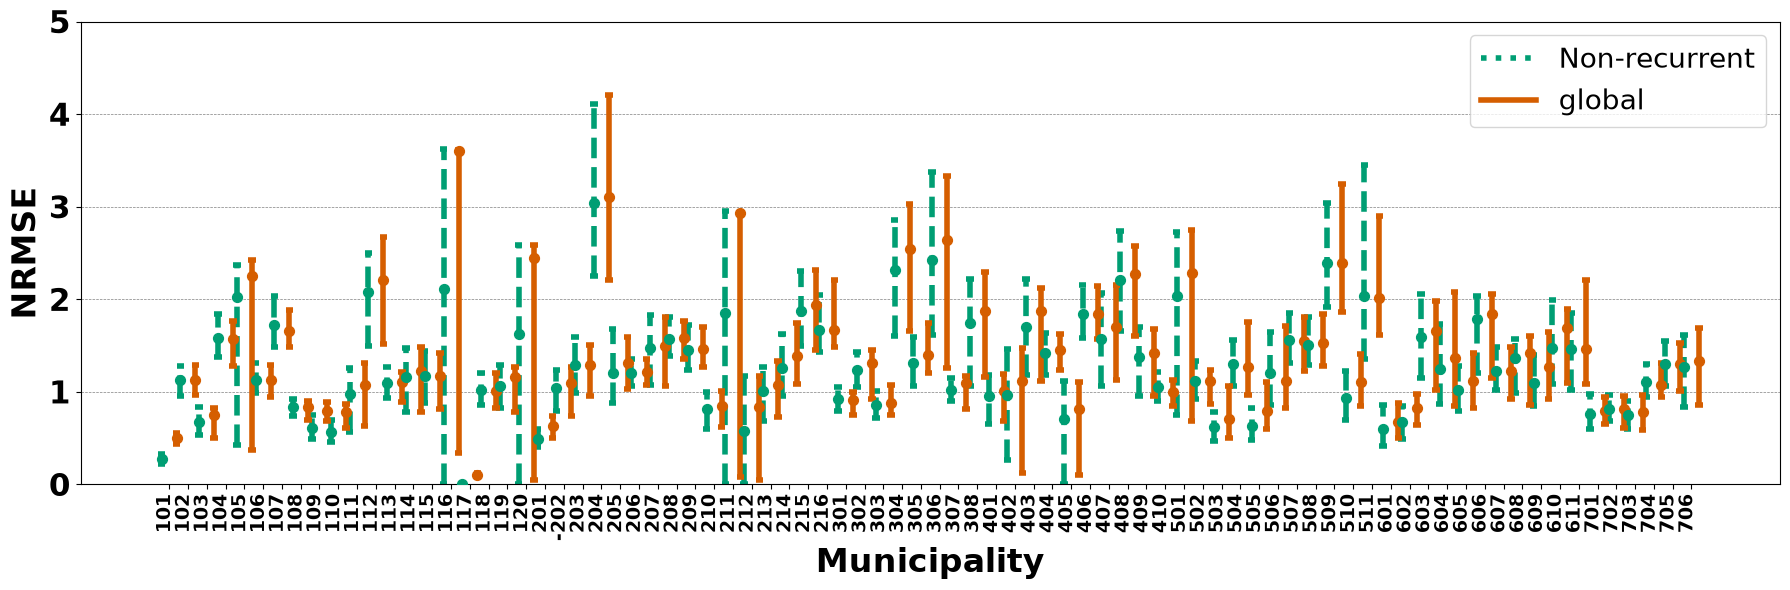

In [9]:
plot_nrmse_confint_past("test", "global")

# NRMSE comparison for global and not global models

In [10]:
def plot_nrmse_confint(dataset):

    confints = pd.read_csv(
            f"../data/metrics/nrmse_lstm_confint.csv"
        )
    
    confint_nofull = confints[["canton", f"{dataset}_point_ind", f"{dataset}_lower_ind",f"{dataset}_upper_ind"]]
    
    confint_nofull["canton"] = confint_nofull["canton"].astype(str)

    confint_full = confints[["canton", f"{dataset}_point_global", f"{dataset}_lower_global",f"{dataset}_upper_global"]]

    confint_full["canton"] = confint_full["canton"].astype(str)

    x = np.arange(len(confint_full))
    
    fig, ax = plt.subplots(figsize=(18, 6))

    cap_width = 0.2

    for i, row in confint_nofull.iterrows():
        # Plotting the individual model NRSME results

        mean_col = f"{dataset}_point_ind"
        lower_col = f"{dataset}_lower_ind"
        upper_col = f"{dataset}_upper_ind"
        
        ax.vlines(
            # Confidence intervals
            x[i],
            row[lower_col],
            row[upper_col],
            color="#009E73",
            linewidth=4,
            linestyles="--"
        )

        # Extremes of the confidence intervals
        ax.hlines(
            row[lower_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4,
        )
        ax.hlines(
            row[upper_col],
            x[i]-cap_width,
            x[i]+cap_width,
            color="#009E73",
            linestyles="--",
            linewidth=4,
        )

        ax.scatter(
            # Plotting the mean as a point
            x[i],
            row[mean_col],
            color="#009E73",
            marker="o",
            s=50,
            zorder=4
        )

    for i, row in confint_full.iterrows():
        # Plotting the global model NRMSE results

        mean_col = f"{dataset}_point_global"
        lower_col = f"{dataset}_lower_global"
        upper_col = f"{dataset}_upper_global"

        x_full = x[i] + 0.8

        ax.vlines(
            # Confidence intervals
            x_full,
            row[lower_col],
            row[upper_col],
            color="#D55E00",
            linewidth=4
        )

        # Extremes of the confidence intervals
        ax.hlines(row[lower_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4) 
        ax.hlines(row[upper_col], 
                  x_full-cap_width, 
                  x_full+cap_width, 
                  color="#D55E00", 
                  linewidth=4)

        ax.scatter(
            # Plotting the mean as a point
            x_full,
            row[mean_col],
            color="#D55E00",
            s=50,
            zorder=3
        )

    # Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
    ax.set_xticks(x + 0.4)
    ax.set_xticklabels(confint_full["canton"], rotation=90, ha="right", fontweight="bold", fontsize = 14)
    dx = 4 / 72.0  
    offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
    for label in ax.get_xticklabels():
        label.set_transform(label.get_transform() + offset)

    style_handles = [
        # Adding the legend
        Line2D([0], [0], color="#009E73", linestyle=":", label="Individual model", linewidth=4),
        Line2D([0], [0], color="#D55E00", linestyle="-", label="Global model", linewidth=4),
    ]

    ax.set_ylabel("NRMSE", fontsize = 24, fontweight="bold")
    ax.set_xlabel("Municipality", fontsize = 24, fontweight="bold")
    ax.set_ylim([0, 5])
    ax.legend(handles=style_handles, fontsize=20, loc="upper right")
    ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")
    plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
    plt.tight_layout()
    plt.show()

C:\Windows\Temp\ipykernel_13972\2821684154.py:123: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


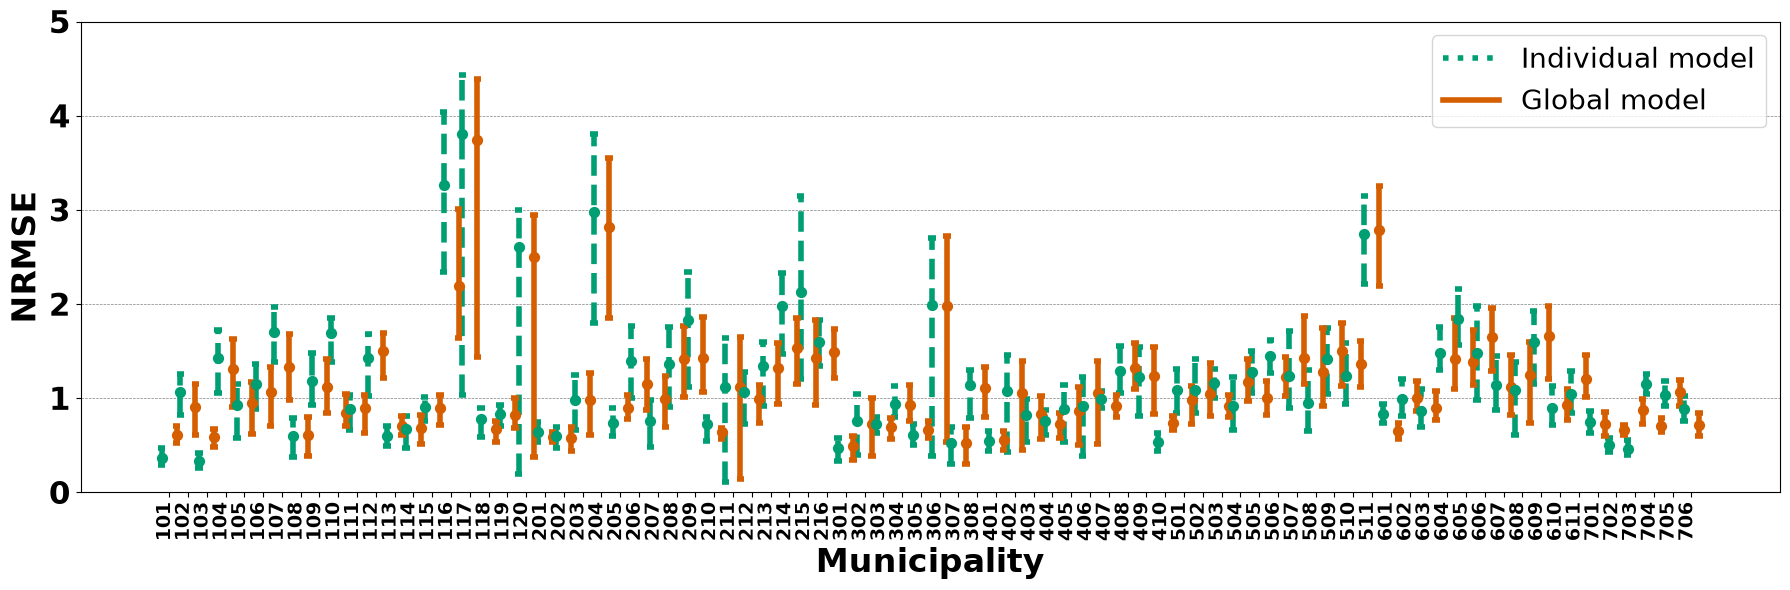

In [11]:
plot_nrmse_confint("train")

C:\Windows\Temp\ipykernel_13972\2821684154.py:123: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 22, fontweight="bold")


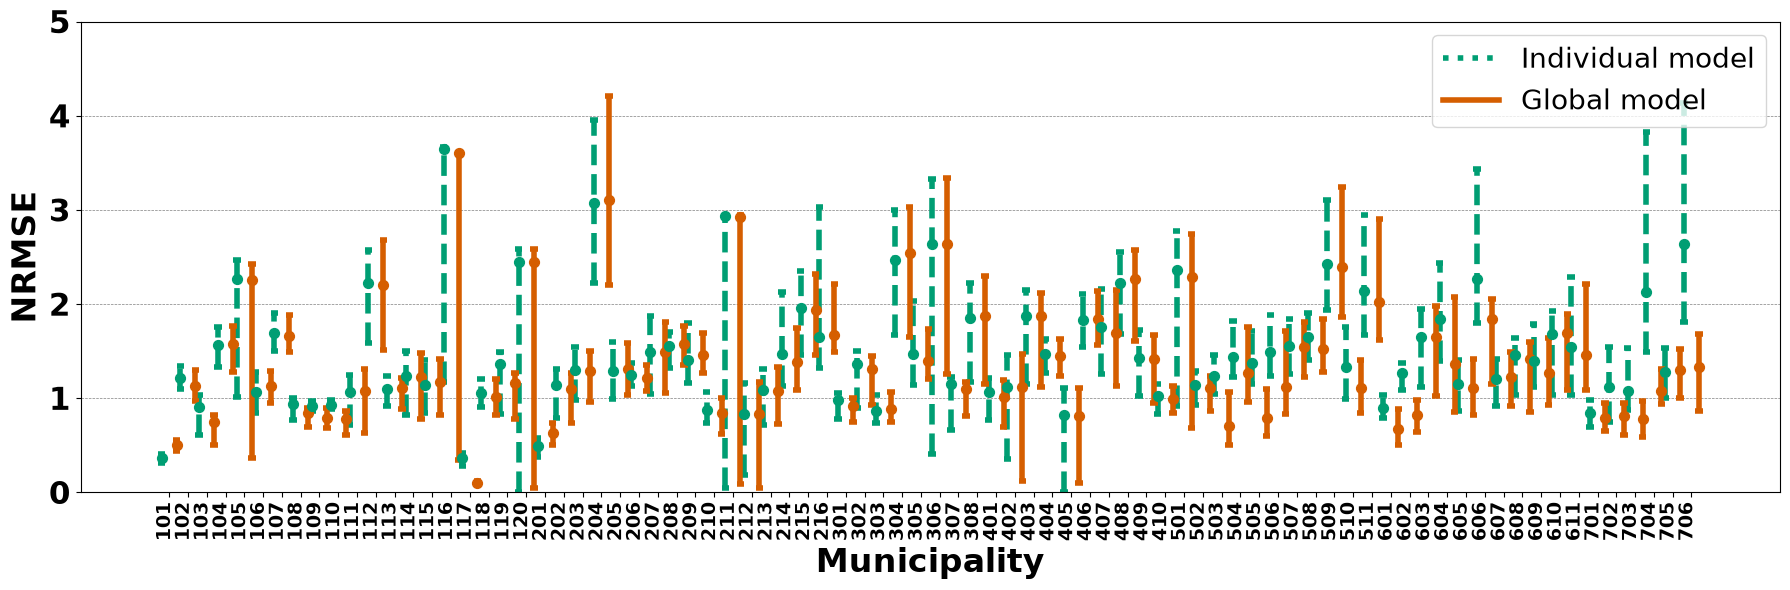

In [12]:
plot_nrmse_confint("test")